# The color wheel as wave mixing

Heiki and I have been learning primary/secondary/tertiary colors on the paint wheel. The idea that pulled me in: each color is a *function of wavelength* (how strongly a pigment reflects each part of the visible spectrum), and mixing two pigments doesn't average those functions -- it **multiplies** them, wavelength by wavelength. Where either pigment fails to reflect, the mixture doesn't either. That's real subtractive-color physics, not a metaphor.

One honest correction to the framing before starting: it's a **pointwise product**, not a convolution (a convolution slides and integrates -- it would *smear* the spectra together rather than sharpen where they overlap). We'll build the real thing first, then look at what a literal convolution would do instead, near the end, as a "what if" comparison.

The payoff Heiki and I noticed with real paint: mix any two *secondary* colors and you get brown, not a third bright color. This notebook builds that up from the wave functions and then shows why it's true -- and visualizes the wavelengths that get cancelled along the way, which your eye never sees in the final swatch.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

WL = np.linspace(380, 700, 321)  # visible spectrum, nm

def gaussian(center, sigma, floor):
    return floor + (1 - floor) * np.exp(-0.5 * ((WL - center) / sigma) ** 2)

def asym_gaussian(center, sigma_left, sigma_right, floor):
    """Different width on each side of the peak -- lets a pigment stay narrow (pure)
    on its lonely side while reaching wide (real overlap) toward one specific neighbor."""
    sigma = np.where(WL < center, sigma_left, sigma_right)
    return floor + (1 - floor) * np.exp(-0.5 * ((WL - center) / sigma) ** 2)

## From reflectance to a color you can see

The first version of this notebook turned a reflectance spectrum into a swatch by looking up each wavelength's own "rainbow" display color and summing -- cheap, but not how vision actually works, and it showed: red pigment came out orange, blue came out cyan. Human color perception integrates a spectrum through three overlapping cone-response curves, not a rainbow lookup table. Using the real thing -- the CIE 1931 standard observer color-matching functions (an analytic fit, Wyman/Sloan/Shirley 2013) -- fixes it.

In [2]:
def cie_xyz(wl):
    """Analytic fit to the CIE 1931 color-matching functions (Wyman/Sloan/Shirley 2013)."""
    t1 = (wl - 442.0) * np.where(wl < 442.0, 0.0624, 0.0374)
    t2 = (wl - 599.8) * np.where(wl < 599.8, 0.0264, 0.0323)
    t3 = (wl - 501.1) * np.where(wl < 501.1, 0.0490, 0.0382)
    x = 0.362 * np.exp(-0.5 * t1 * t1) + 1.056 * np.exp(-0.5 * t2 * t2) - 0.065 * np.exp(-0.5 * t3 * t3)
    u1 = (wl - 568.8) * np.where(wl < 568.8, 0.0213, 0.0247)
    u2 = (wl - 530.9) * np.where(wl < 530.9, 0.0613, 0.0322)
    y = 0.821 * np.exp(-0.5 * u1 * u1) + 0.286 * np.exp(-0.5 * u2 * u2)
    v1 = (wl - 437.0) * np.where(wl < 437.0, 0.0845, 0.0278)
    v2 = (wl - 459.0) * np.where(wl < 459.0, 0.0385, 0.0725)
    z = 1.217 * np.exp(-0.5 * v1 * v1) + 0.681 * np.exp(-0.5 * v2 * v2)
    return x, y, z

X_, Y_, Z_ = cie_xyz(WL)
XYZ_TO_SRGB = np.array([
    [ 3.2406, -1.5372, -0.4986],
    [-0.9689,  1.8758,  0.0415],
    [ 0.0557, -0.2040,  1.0570],
])
WHITE_Y = Y_.sum()  # luminance of a flat (equal-energy) reference white

def raw_linear_rgb(spectrum):
    xyz = np.array([(spectrum * X_).sum(), (spectrum * Y_).sum(), (spectrum * Z_).sum()]) / WHITE_Y
    return np.maximum(XYZ_TO_SRGB @ xyz, 0)

def swatch(spectrum, scale):
    """scale is shared across the whole notebook so that darker mixtures really do render darker,
    not renormalized back up to full brightness -- that darkening IS the finding."""
    lin = raw_linear_rgb(spectrum) * scale
    peak = lin.max()
    if peak > 1:
        lin = lin / peak
    srgb = np.where(lin <= 0.0031308, 12.92 * lin, 1.055 * lin ** (1 / 2.4) - 0.055)
    return np.clip(srgb, 0, 1)

def show_swatches(names_spectra, scale, title):
    fig, axes = plt.subplots(1, len(names_spectra), figsize=(2.2 * len(names_spectra), 2.4))
    if len(names_spectra) == 1:
        axes = [axes]
    for ax, (name, spec) in zip(axes, names_spectra):
        ax.imshow([[swatch(spec, scale)]])
        ax.set_title(name, fontsize=11)
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout(rect=[0, 0, 1, 0.90])
    return fig

## The three primaries

Red and yellow are narrow, symmetric bumps -- nothing forces them wide. Blue and yellow are the pair that needs to *overlap* (to make green), so yellow is widened only on the sides facing its neighbors, and blue only on the side facing yellow -- not widened all around, which is what was blurring blue toward cyan before. `floor` keeps every pigment reflecting a little everywhere, matching how real pigments are imperfect absorbers.

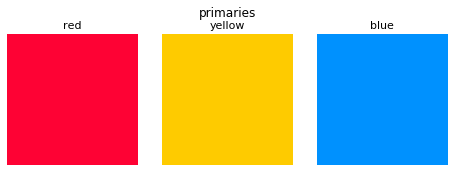

In [3]:
RED    = gaussian(650, 25, 0.03)
BLUE   = asym_gaussian(460, 20, 40, 0.03)     # wide only toward yellow
YELLOW = asym_gaussian(580, 40, 45, 0.03)     # wide toward both neighbors
SCALE  = 5.0 / raw_linear_rgb(RED).max()      # calibrated so a pure primary just reaches full brightness

show_swatches([("red", RED), ("yellow", YELLOW), ("blue", BLUE)], SCALE, "primaries")
plt.savefig("color_wheel_primaries.png", dpi=100)
plt.show()

## Secondaries: multiply the wave functions

Orange and green are the overlap of two *adjacent* primaries, so their product stays bright: red and yellow both reflect strongly around 600-650nm, and that shared region survives the multiplication.

Purple is the interesting exception. Red (650nm) and blue (460nm) sit at opposite ends of a spectrum that's a straight *line*, not a circle -- there's no wavelength "between" them the way there's a wavelength between red and yellow. Multiplying their curves lands in that gap and comes out a muddy yellow-green, not purple. Check it below.

In [4]:
PURPLE_naive = RED * BLUE
print("red x blue, multiplied directly:", swatch(PURPLE_naive, SCALE).round(2), "-- not purple.")

red x blue, multiplied directly: [0.37 0.24 0.47] -- not purple.


That's not a bug, it's the well-known fact that purple/magenta is **non-spectral** -- no single wavelength looks purple. Your eye invents it by firing its long- and short-wavelength cones at once with the middle ones quiet, which is exactly why the artist's color wheel is drawn as a *circle*: it bends the wavelength line around and glues the two ends together through a hue that was never really "in between" them on the spectrum. Real violet pigments have their own two-humped reflectance curve (reflect deep red, reflect violet, absorb the green in between) rather than being built out of red and blue pigment. We give purple that shape directly instead of forcing it out of the red/blue product.

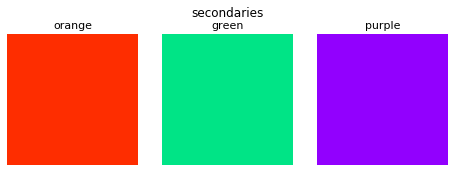

In [5]:
PURPLE = np.maximum(gaussian(695, 20, 0.03), gaussian(420, 20, 0.03))   # two humps, real dip through green
ORANGE = RED * YELLOW
GREEN  = YELLOW * BLUE

show_swatches([("orange", ORANGE), ("green", GREEN), ("purple", PURPLE)], SCALE, "secondaries")
plt.savefig("color_wheel_secondaries.png", dpi=100)
plt.show()

## Why any two secondaries turn muddy

Each secondary is built from exactly two of the three primaries: orange = red+yellow, green = yellow+blue, purple = blue+red. There are only three primaries and three secondaries, so **any two secondaries, taken together, are guaranteed to touch all three primaries** -- one primary gets used twice, but none get left out. Cheap combinatorial check first, before trusting the pretty pictures:

In [6]:
PRIMARIES_OF = {"orange": {"red", "yellow"}, "green": {"yellow", "blue"}, "purple": {"blue", "red"}}
import itertools
for a, b in itertools.combinations(PRIMARIES_OF, 2):
    covered = PRIMARIES_OF[a] | PRIMARIES_OF[b]
    assert covered == {"red", "yellow", "blue"}, f"{a}+{b} misses a primary: {covered}"
print("confirmed: every pair of secondaries jointly covers all three primaries")

confirmed: every pair of secondaries jointly covers all three primaries


Multiplying spectra that between them span all three primaries multiplies down every wavelength band at least once -- there's no region left where the mixture still reflects strongly. Low, broad, roughly-flat reflectance is what a *muddy, low-chroma* color looks like -- painters just call it "mud." It isn't always the same hue: how much of the spectrum actually gets cancelled depends on how far apart that specific pair sits in wavelength (orange and green are far apart and cancel hard; orange and purple's red lobe are closer together and cancel less completely), so the result lands anywhere from brown to a dark maroon to a dark slate -- never a third bright color, always dark and desaturated.

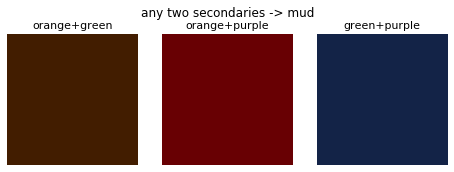

In [7]:
pairs = [("orange", ORANGE, "green", GREEN), ("orange", ORANGE, "purple", PURPLE), ("green", GREEN, "purple", PURPLE)]
mixes = [(f"{n1}+{n2}", s1 * s2) for n1, s1, n2, s2 in pairs]
show_swatches(mixes, SCALE, "any two secondaries -> mud")
plt.savefig("color_wheel_mud.png", dpi=100)
plt.show()

## The recipe, spelled out

The assert above proves the primary-coverage claim in words; here's the same fact as reflectance curves, same style as the rest of this notebook. Each secondary decomposes back into the two primaries that built it -- plot all three primaries for a given pair of secondaries and the same three curves show up every time (that's the pigeonhole guarantee), just with a different one drawn bold because that's the one the pair happens to share.

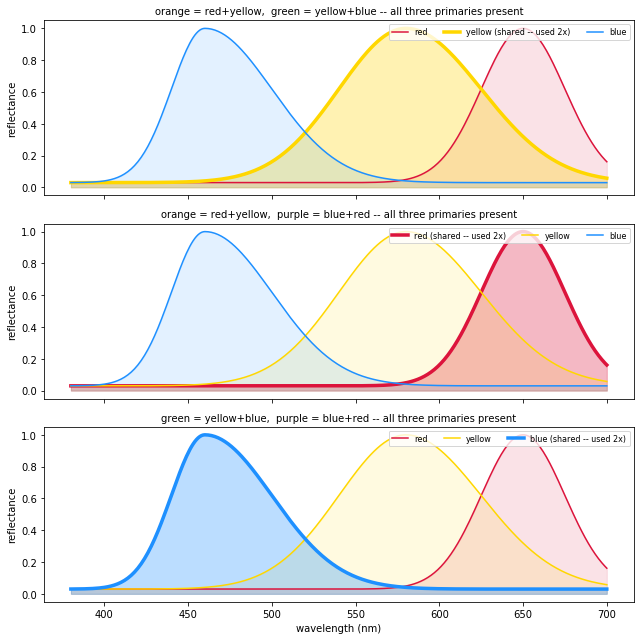

In [8]:
from collections import Counter

FORMED_FROM = {"orange": ("red", "yellow"), "green": ("yellow", "blue"), "purple": ("blue", "red")}
PRIMARY = {"red": RED, "yellow": YELLOW, "blue": BLUE}
PRIMARY_COLOR = {"red": "crimson", "yellow": "gold", "blue": "dodgerblue"}
row_pairs = [("orange", "green"), ("orange", "purple"), ("green", "purple")]

fig, axes = plt.subplots(len(row_pairs), 1, figsize=(9, 9), sharex=True)
for ax, (a, b) in zip(axes, row_pairs):
    counts = Counter(FORMED_FROM[a] + FORMED_FROM[b])
    for name in ["red", "yellow", "blue"]:
        n = counts[name]
        lw = 3.5 if n == 2 else 1.5
        ax.plot(WL, PRIMARY[name], color=PRIMARY_COLOR[name], lw=lw,
                 label=f"{name} (shared -- used 2x)" if n == 2 else name)
        ax.fill_between(WL, PRIMARY[name], color=PRIMARY_COLOR[name], alpha=0.3 if n == 2 else 0.12)
    ax.set_ylabel("reflectance")
    ax.legend(fontsize=8, loc="upper right", ncol=3)
    ax.set_title(f"{a} = {'+'.join(FORMED_FROM[a])},  {b} = {'+'.join(FORMED_FROM[b])} -- all three primaries present", fontsize=10)
axes[-1].set_xlabel("wavelength (nm)")
plt.tight_layout()
plt.savefig("color_wheel_recipe.png", dpi=100)
plt.show()

## Opposite colors on the wheel: no doubling needed

The pairs above (any two secondaries) always double one primary. There's a cleaner case: a secondary mixed with its exact opposite on the wheel. Primaries and secondaries alternate around the wheel, so a secondary's true 180-degree opposite is always the *one primary it's missing* -- orange's opposite is blue, green's is red, purple's is yellow. Mix a secondary with that opposite and you get red, yellow, and blue each showing up exactly **once**, no doubling at all -- and it still goes brown. That's actually a purer demonstration than the secondary-secondary case: even the most evenly-balanced possible combination of the three primaries still cancels down to mud, because "balanced" was never the thing preventing cancellation -- full coverage was.

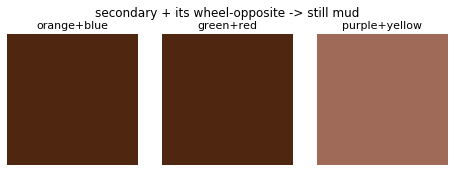

orange x blue and green x red are the same spectrum: True


In [9]:
opposite_pairs = [("orange", ORANGE, "blue", BLUE), ("green", GREEN, "red", RED), ("purple", PURPLE, "yellow", YELLOW)]
opposite_mixes = [(f"{n1}+{n2}", s1 * s2) for n1, s1, n2, s2 in opposite_pairs]
show_swatches(opposite_mixes, SCALE, "secondary + its wheel-opposite -> still mud")
plt.savefig("color_wheel_opposite_mud.png", dpi=100)
plt.show()

# orange = red*yellow, so orange*blue = red*yellow*blue -- and green*red is the exact same product
# (green = yellow*blue, so green*red = yellow*blue*red too). Two different-looking wheel-opposite
# pairs, algebraically the identical mixture.
print("orange x blue and green x red are the same spectrum:", np.allclose(ORANGE * BLUE, GREEN * RED))

Same wavelength-domain view as before, this time for orange and its opposite:

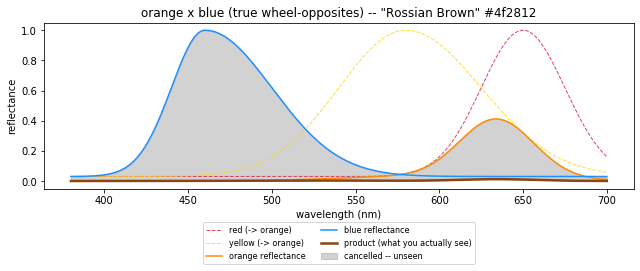

orange x blue, the real opposite-colors mud: [0.311 0.157 0.069] = #4f2812, official name Rossian Brown


In [19]:
import matplotlib.colors as mcolors

A, B, label_a, label_b = ORANGE, BLUE, "orange", "blue"
product = A * B
envelope = np.maximum(A, B)
mud_rgb = swatch(product, SCALE)
mud_hex = mcolors.to_hex(mud_rgb)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(WL, RED,    color="crimson",    lw=1, alpha=0.8, ls="--", label="red (-> orange)")
ax.plot(WL, YELLOW, color="gold",       lw=1, alpha=0.8, ls="--", label="yellow (-> orange)")
ax.plot(WL, A, color="darkorange", label=f"{label_a} reflectance", lw=1.5)
ax.plot(WL, B, color="dodgerblue", label=f"{label_b} reflectance", lw=1.5)
ax.plot(WL, product, color="saddlebrown", lw=2.5, label="product (what you actually see)")
ax.fill_between(WL, product, envelope, color="gray", alpha=0.35, label="cancelled -- unseen")
ax.set_xlabel("wavelength (nm)")
ax.set_ylabel("reflectance")
ax.legend(fontsize=8, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.18))
ax.set_title(f'{label_a} x {label_b} (true wheel-opposites) -- "Rossian Brown" {mud_hex}')
plt.tight_layout()
plt.savefig("color_wheel_opposite_unseen.png", dpi=100, bbox_inches="tight")
plt.show()
print(f"orange x blue, the real opposite-colors mud: {mud_rgb.round(3)} = {mud_hex}, official name Rossian Brown")

Same pair, other operation -- add instead of multiply, same visual grammar as before (`min` instead of `max`, "gained" instead of "cancelled"). Worth computing rather than assuming it lands on white just because it's the flip side of a brown: addition can only ever fill in, never erase, so a real gap between two peaks -- and orange (peak ~634nm) and blue (peak ~460nm) leave a big one, nothing covering roughly 490-580nm strongly -- just stays a gap. The printed swatch below is the honest answer, not a forced one.

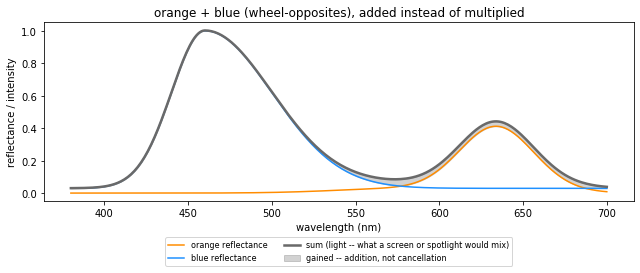

orange+blue, summed, rendered color: [0.59 0.58 1.  ] -- not neutral: real gap around 500-580nm, unlike blue+yellow.


In [11]:
additive = A + B
gained = additive - np.maximum(A, B)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(WL, A, color="darkorange", label=f"{label_a} reflectance", lw=1.5)
ax.plot(WL, B, color="dodgerblue", label=f"{label_b} reflectance", lw=1.5)
ax.plot(WL, additive, color="dimgray", lw=2.5, label="sum (light -- what a screen or spotlight would mix)")
ax.fill_between(WL, np.maximum(A, B), additive, color="gray", alpha=0.35, label="gained -- addition, not cancellation")
ax.set_xlabel("wavelength (nm)")
ax.set_ylabel("reflectance / intensity")
ax.legend(fontsize=8, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.18))
ax.set_title(f"{label_a} + {label_b} (wheel-opposites), added instead of multiplied")
plt.tight_layout()
plt.savefig("color_wheel_opposite_additive.png", dpi=100, bbox_inches="tight")
plt.show()
print(f"{label_a}+{label_b}, summed, rendered color:", swatch(additive, SCALE / 2).round(2), "-- not neutral: real gap around 500-580nm, unlike blue+yellow.")

So the brown-to-white symmetry doesn't hold for every pair -- multiplication cancelled orange and blue almost completely (any wavelength either one skipped, the product skips too), but addition only fills in where at least one of them already reflects, and neither reflects much through the middle of the spectrum, so that gap survives as a visible dip and the sum reads as a pale, cool lavender-blue, not neutral. The one pair that actually got to near-white earlier -- blue and yellow -- worked for a specific reason: yellow's wide tails happen to bridge exactly the gap that's stranding orange and blue here. Being "opposite on the wheel" cancels reliably under multiplication; it does not neutralize reliably under addition unless the curves themselves also happen to cover the full spectrum between them.

## Visualizing the unseen: what gets cancelled

The swatch above only shows the *survivor* -- the light that makes it through both pigments. Overlay the two input spectra against their product and the gap between "what either pigment alone would have reflected" (the envelope, `max(A, B)`) and "what actually gets through" (`A * B`) is the part of the mixing your eye never sees directly: wavelengths one pigment was happy to reflect that the other one absorbed away. Faint in the background: the primaries one level further down -- red and yellow behind orange, blue and yellow behind green, since orange and green are themselves already a mixing product.

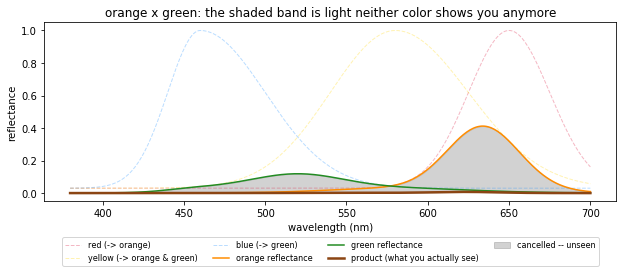

In [12]:
A, B, label_a, label_b = ORANGE, GREEN, "orange", "green"
product = A * B
envelope = np.maximum(A, B)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(WL, RED,    color="crimson",     lw=1, alpha=0.3, ls="--", label="red (-> orange)")
ax.plot(WL, YELLOW, color="gold",        lw=1, alpha=0.3, ls="--", label="yellow (-> orange & green)")
ax.plot(WL, BLUE,   color="dodgerblue",  lw=1, alpha=0.3, ls="--", label="blue (-> green)")
ax.plot(WL, A, color="darkorange", label=f"{label_a} reflectance", lw=1.5)
ax.plot(WL, B, color="forestgreen", label=f"{label_b} reflectance", lw=1.5)
ax.plot(WL, product, color="saddlebrown", lw=2.5, label="product (what you actually see)")
ax.fill_between(WL, product, envelope, color="gray", alpha=0.35, label="cancelled -- unseen")
ax.set_xlabel("wavelength (nm)")
ax.set_ylabel("reflectance")
ax.legend(fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.18))
ax.set_title(f"{label_a} x {label_b}: the shaded band is light neither color shows you anymore")
plt.tight_layout()
plt.savefig("color_wheel_unseen.png", dpi=100, bbox_inches="tight")
plt.show()

## What if it really were a convolution?

It isn't -- subtractive mixing is the pointwise product above. But since the original hunch was "convolution," it's worth actually computing one and seeing why it's the wrong operation: convolution slides one spectrum across the other and integrates the overlap at each offset, which **spreads** a signal out rather than sharpening it toward the overlap. Multiplication *sharpens toward agreement*; convolution *smears*.

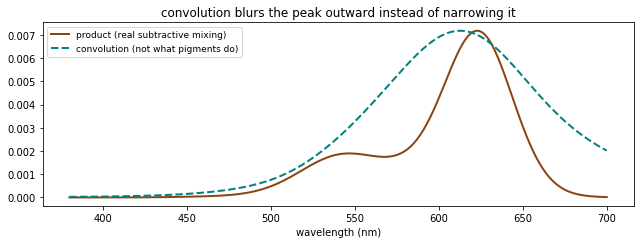

In [13]:
conv = np.convolve(A, B, mode="same")
conv = conv / conv.max() * product.max()   # match scale for a fair shape comparison

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(WL, product, color="saddlebrown", lw=2, label="product (real subtractive mixing)")
ax.plot(WL, conv, color="teal", lw=2, ls="--", label="convolution (not what pigments do)")
ax.set_xlabel("wavelength (nm)")
ax.legend(fontsize=9)
ax.set_title("convolution blurs the peak outward instead of narrowing it")
plt.tight_layout()
plt.savefig("color_wheel_convolution_vs_product.png", dpi=100)
plt.show()

## The full wheel

Tertiaries fill the gaps between each primary and its neighboring secondary, built the same way -- multiply the two neighbors' curves (purple's tertiaries multiply its bimodal curve against blue or red, same rule, no special case).

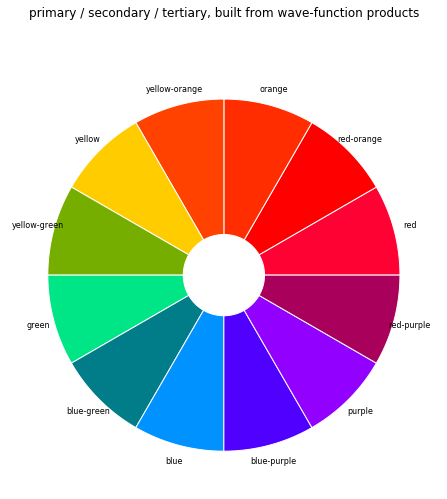

In [14]:
WHEEL = [
    ("red", RED), ("red-orange", RED * ORANGE), ("orange", ORANGE), ("yellow-orange", YELLOW * ORANGE),
    ("yellow", YELLOW), ("yellow-green", YELLOW * GREEN), ("green", GREEN), ("blue-green", BLUE * GREEN),
    ("blue", BLUE), ("blue-purple", BLUE * PURPLE), ("purple", PURPLE), ("red-purple", RED * PURPLE),
]

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={"projection": "polar"})
n = len(WHEEL)
width = 2 * np.pi / n
for i, (name, spec) in enumerate(WHEEL):
    theta = i * width
    ax.bar(theta, 1, width=width, bottom=0.3, color=swatch(spec, SCALE), edgecolor="white", linewidth=1, align="edge")
    ax.text(theta + width / 2, 1.42, name, ha="center", va="center", fontsize=8, rotation=0)
ax.set_ylim(0, 1.6)
ax.axis("off")
ax.set_title("primary / secondary / tertiary, built from wave-function products", pad=20)
plt.tight_layout()
plt.savefig("color_wheel_full.png", dpi=100)
plt.show()

## The same two ingredients, the other operation

Blue and yellow, multiplied, made green a few sections back -- that's real subtractive mixing, how pigment works. There's a second real physical operation sitting right next to it: addition, how *light* works (a screen, a spotlight, two overlapping beams). Same two ingredients, different operation, and it's worth actually computing rather than asserting: `BLUE + YELLOW` (summed, not multiplied) comes out close to neutral white/gray in this model, not green and not brown. Same structure as the cancellation figure above -- two input curves, a combined curve, a shaded highlight -- just with the one operation swapped for the other.

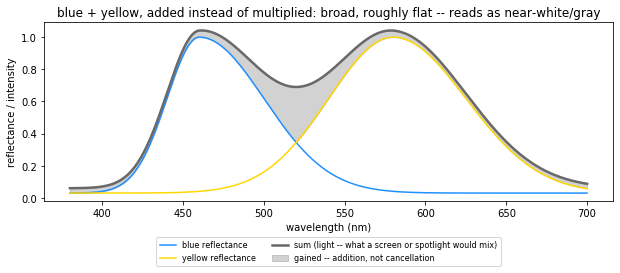

blue+yellow, summed, rendered color: [1.   0.95 0.87]


In [15]:
C, D, label_c, label_d = BLUE, YELLOW, "blue", "yellow"
additive = C + D
overlap = np.minimum(C, D)   # the part both curves already agreed on, before adding anything new

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(WL, C, color="dodgerblue", label=f"{label_c} reflectance", lw=1.5)
ax.plot(WL, D, color="gold", label=f"{label_d} reflectance", lw=1.5)
ax.plot(WL, additive, color="dimgray", lw=2.5, label="sum (light -- what a screen or spotlight would mix)")
ax.fill_between(WL, np.maximum(C, D), additive, color="gray", alpha=0.35, label="gained -- addition, not cancellation")
ax.set_xlabel("wavelength (nm)")
ax.set_ylabel("reflectance / intensity")
ax.legend(fontsize=8, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.18))
ax.set_title(f"{label_c} + {label_d}, added instead of multiplied: broad, roughly flat -- reads as near-white/gray")
plt.tight_layout()
plt.savefig("color_wheel_additive_gray.png", dpi=100, bbox_inches="tight")
plt.show()
print("blue+yellow, summed, rendered color:", swatch(additive, SCALE / 2).round(2))

Multiplying spectra can only ever remove -- the product is small wherever either input is small, which is how the mud swatches went dark. Adding spectra can only ever fill in -- the sum is at least as big as the bigger input everywhere, so a broad enough pair of "opposite ends of the spectrum" curves ends up covering the whole visible range fairly evenly, and a roughly flat spectrum is what reads as white or gray rather than any one hue. Same two colors, opposite operation, opposite outcome -- brown from one, near-white from the other.

## Just for fun: the whole wheel, both ways

Same colors built through this whole notebook -- red, yellow, blue first, orange and green riding in between them -- added together instead of picked two at a time. Purple was the odd one out here: it's the only curve in this notebook built from two humps instead of one (that's what made it purple in the first place -- see the non-spectral discussion above), and stacking a two-humped curve into a sum quietly double-weights whatever it's near. Split it back into its real spectral ingredients instead -- indigo and violet, the two named colors purple was standing in for -- so every curve going into this sum is single-peaked, like the rest of the notebook already assumes.

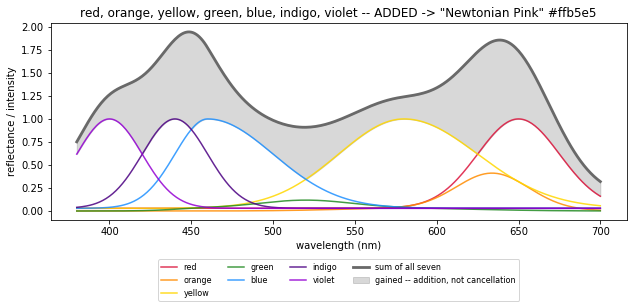

naive equal-weight sum of all seven: [1.    0.71  0.897] = #ffb5e5, official name Newtonian Pink


In [16]:
import matplotlib.colors as mcolors

INDIGO = gaussian(440, 20, 0.03)
VIOLET = gaussian(400, 20, 0.03)

seven = [("red", RED, "crimson"), ("orange", ORANGE, "darkorange"), ("yellow", YELLOW, "gold"),
         ("green", GREEN, "forestgreen"), ("blue", BLUE, "dodgerblue"), ("indigo", INDIGO, "indigo"),
         ("violet", VIOLET, "darkviolet")]
naive_sum = sum(v for _, v, _ in seven)
naive_envelope = np.maximum.reduce([v for _, v, _ in seven])

fig, ax = plt.subplots(figsize=(9, 4.5))
for name, curve, color in seven:
    ax.plot(WL, curve, color=color, lw=1.5, alpha=0.85, label=name)
ax.plot(WL, naive_sum, color="dimgray", lw=2.8, label="sum of all seven")
ax.fill_between(WL, naive_envelope, naive_sum, color="gray", alpha=0.3, label="gained -- addition, not cancellation")
ax.set_xlabel("wavelength (nm)")
ax.set_ylabel("reflectance / intensity")
ax.legend(fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.18))
naive_rgb = swatch(naive_sum, SCALE / 3.5)
naive_hex = mcolors.to_hex(naive_rgb)
ax.set_title(f'red, orange, yellow, green, blue, indigo, violet -- ADDED -> "Newtonian Pink" {naive_hex}')
plt.tight_layout()
plt.savefig("color_wheel_roygbiv_naive.png", dpi=110, bbox_inches="tight")
plt.show()
print(f"naive equal-weight sum of all seven: {naive_rgb.round(3)} = {naive_hex}, official name Newtonian Pink")

**Newtonian Pink**, official hex `#ffb5e5` -- that's worse, not better, more blue-violet than the six-color version, not less. The reason is real: blue, indigo, and violet are three separate named colors packed into the *short* end of the spectrum (roughly 380-495nm, about 115nm total), while red alone covers a wider band by itself (roughly 620-750nm, about 130nm) with no second or third name to split the difference. Add "one of each name" and the short end gets triple representation for barely more spectrum than red gets with one. Newton's seven names were never spaced to make that fair -- he picked seven specifically to match the seven notes of a musical scale, a numerological choice, not a physical one (indigo in particular is the band most people still can't reliably pick out on its own). ROYGBIV is a *label*, not a *recipe*.

The paint wheel is the opposite: red, yellow, and blue were never derived from wavelength physics at all. They're the output of centuries of painters actually mixing pigments and writing down what produced what -- the wheel *is* the calibration, reverse-engineered from real mixing behavior until "red + yellow = orange" reliably held. That's why the pigment side of this notebook never had to fight this problem: it was built backward from the answer. The wavelength side has to earn it, by weighting each named color by how much of the real spectrum it actually stands for instead of treating every name as an equal-sized slice.

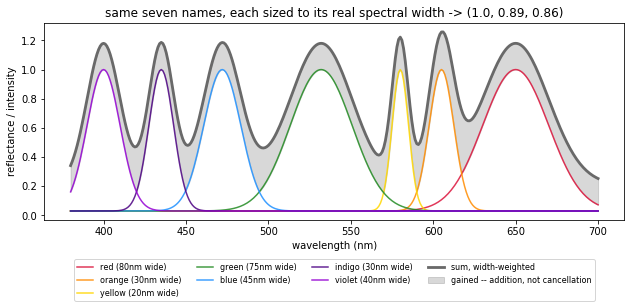

width-weighted sum of all seven: [1.    0.891 0.864]


In [17]:
# each band's real width in nm (standard ROYGBIV boundaries), sigma sized proportionally --
# every curve single-peaked and full-amplitude, unlike the pigment-mixing ORANGE/GREEN products
bands = {"red": (650, 80), "orange": (605, 30), "yellow": (580, 20), "green": (532, 75),
         "blue": (472, 45), "indigo": (435, 30), "violet": (400, 40)}
band_colors = {"red": "crimson", "orange": "darkorange", "yellow": "gold", "green": "forestgreen",
               "blue": "dodgerblue", "indigo": "indigo", "violet": "darkviolet"}
weighted_curves = {name: gaussian(center, width / 4, 0.03) for name, (center, width) in bands.items()}
weighted_sum = sum(weighted_curves.values())
weighted_envelope = np.maximum.reduce(list(weighted_curves.values()))

fig, ax = plt.subplots(figsize=(9, 4.5))
for name, curve in weighted_curves.items():
    ax.plot(WL, curve, color=band_colors[name], lw=1.5, alpha=0.85,
             label=f"{name} ({bands[name][1]}nm wide)")
ax.plot(WL, weighted_sum, color="dimgray", lw=2.8, label="sum, width-weighted")
ax.fill_between(WL, weighted_envelope, weighted_sum, color="gray", alpha=0.3, label="gained -- addition, not cancellation")
ax.set_xlabel("wavelength (nm)")
ax.set_ylabel("reflectance / intensity")
ax.legend(fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.18))
weighted_rgb = swatch(weighted_sum, SCALE / 3.5)
ax.set_title(f"same seven names, each sized to its real spectral width -> {tuple(weighted_rgb.round(2))}")
plt.tight_layout()
plt.savefig("color_wheel_roygbiv_weighted.png", dpi=110, bbox_inches="tight")
plt.show()
print("width-weighted sum of all seven:", weighted_rgb.round(3))

Much closer to neutral -- still not perfectly flat (seven bands is still a coarse approximation of a continuum, same honesty-not-forced spirit as every other number in this notebook), but the gap between R, G, and B shrank by roughly half just from sizing each curve to the spectrum it's actually supposed to represent, nothing else changed. Multiplication doesn't care about any of this -- the same seven colors multiplied together collapse to black regardless of how they're weighted, since one real gap from any single curve erases a wavelength for good:

In [18]:
all_product = np.ones_like(WL)
for _, curve, _ in seven:
    all_product = all_product * curve
print("all seven, multiplied, peak reflectance:", all_product.max())
print("all seven, multiplied, rendered color:", swatch(all_product, SCALE).round(4), "-- indistinguishable from black at any real display brightness")

all seven, multiplied, peak reflectance: 7.532841669260226e-08
all seven, multiplied, rendered color: [0. 0. 0.] -- indistinguishable from black at any real display brightness


Weighted correctly, the whole spectrum added together is white. The same whole spectrum multiplied together is far darker than "brown" even means -- brown was always the gentle version of this, using two or three colors instead of seven. Same light, two operations, two different worlds -- exactly Eugenia Cheng's point, just made out of wavelengths instead of numbers.

## What's real here and what's stylized

Real: subtractive pigment mixing is a pointwise product of reflectance spectra (not an average, not a convolution); additive light mixing is a real, different, sum operation, not a stylistic choice; orange and green come straight out of the product using their true adjacent-primary wavelengths, and blue+yellow summed instead of multiplied genuinely computes to near-neutral; any two secondaries provably span all three primaries, which is *why* they mud out; converting a spectrum to a color you can see is done with the actual CIE 1931 color-matching functions, not a rainbow-lookup shortcut (the shortcut was the bug that made the first version's red look orange and blue look cyan). Stylized: the exact reflectance curves are hand-built Gaussians tuned to look right, not measured pigment data; yellow and blue are deliberately asymmetric (wide only toward each other) so green survives without diluting blue's own purity; purple's bimodal curve is a deliberate reconstruction rather than derived from red and blue the way orange and green were -- all flagged above, not hidden.